# Day 5 — Hourly Demand Forecasting


## 1. Imports and paths

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "demand_forecasting"
MODELS = ROOT / "models"
for p in [PROCESSED, OUT, MODELS]:
    p.mkdir(parents=True, exist_ok=True)

## 2. Prepare hourly demand

In [2]:
orders_path = RAW / "orders.csv"
if not orders_path.exists():
    raise FileNotFoundError(f"Place orders.csv in {RAW}")
orders = pd.read_csv(orders_path)
time_col = next((c for c in ["order_timestamp","order_time","created_at","order_date","timestamp"] if c in orders.columns), None)
if time_col is None:
    raise ValueError(f"Timestamp column not found. Columns: {orders.columns.tolist()}")
orders[time_col] = pd.to_datetime(orders[time_col], errors="coerce")
orders = orders.dropna(subset=[time_col]).sort_values(time_col).set_index(time_col)
hourly = orders.resample("h").size().rename("order_count").asfreq("h", fill_value=0).to_frame()
hourly.index.name = "hour"
hourly.to_csv(PROCESSED / "hourly_order_demand.csv")
display(hourly.head())
print("Rows:", len(hourly), "Period:", hourly.index.min(), "to", hourly.index.max())

,order_count
hour,
2026-01-01 01:00:00,2
2026-01-01 02:00:00,2
2026-01-01 03:00:00,0
2026-01-01 04:00:00,0
2026-01-01 05:00:00,3


Rows: 2158 Period: 2026-01-01 01:00:00 to 2026-03-31 22:00:00


## 3. Trends, hourly and weekday patterns

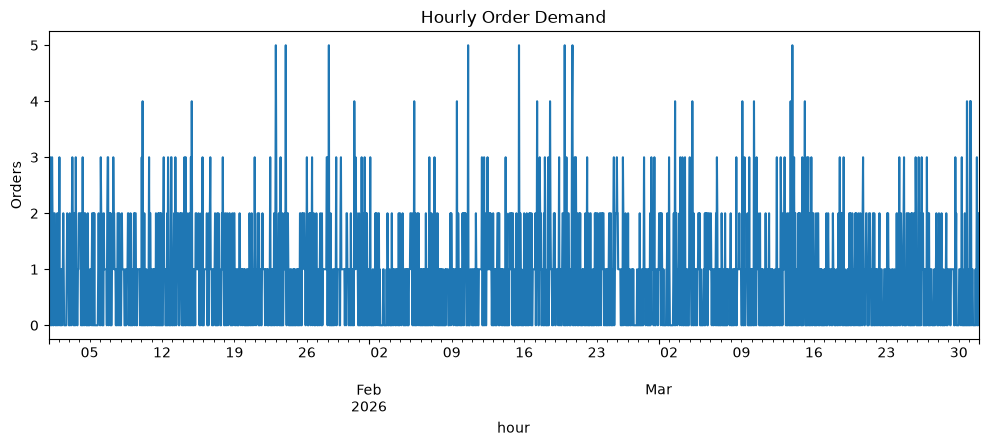

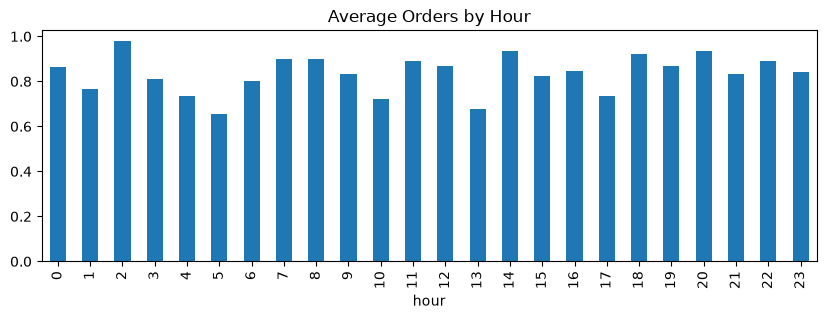

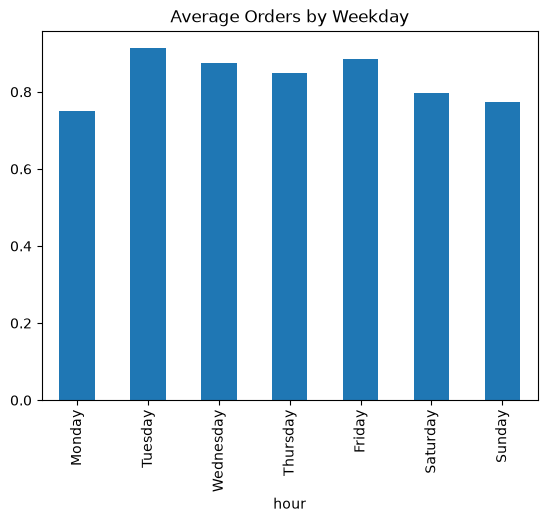

Peak average hour: 2 Average orders: 0.98


In [3]:
hourly["order_count"].plot(figsize=(12,4), title="Hourly Order Demand")
plt.ylabel("Orders"); plt.show()
by_hour = hourly.groupby(hourly.index.hour)["order_count"].mean()
by_day = hourly.groupby(hourly.index.day_name())["order_count"].mean()
by_hour.plot(kind="bar", figsize=(10,3), title="Average Orders by Hour"); plt.show()
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
by_day.reindex([d for d in day_order if d in by_day.index]).plot(kind="bar", title="Average Orders by Weekday")
plt.show()
print("Peak average hour:", int(by_hour.idxmax()), "Average orders:", round(float(by_hour.max()),2))

## 4. Decomposition and stationarity

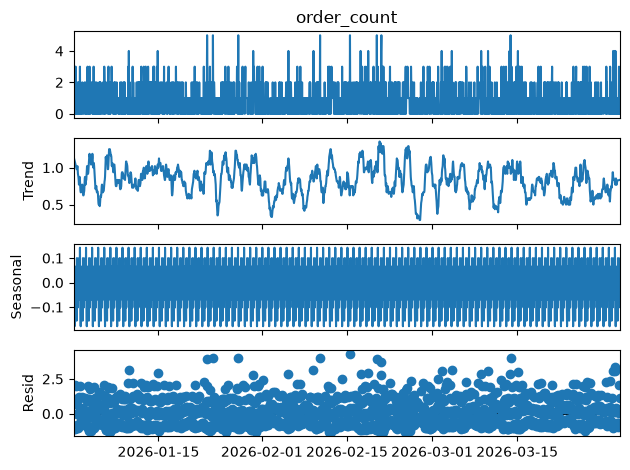

ADF statistic: -46.9188 p-value: 0.0
Stationary at 5% level
First-difference ADF p-value: 0.0


In [4]:
if len(hourly) >= 48:
    decomposition = seasonal_decompose(hourly["order_count"], model="additive", period=24, extrapolate_trend="freq")
    decomposition.plot(); plt.tight_layout(); plt.show()
    pd.DataFrame({"trend":decomposition.trend,"seasonal":decomposition.seasonal,"residual":decomposition.resid}).to_csv(OUT/"time_series_decomposition.csv")
else:
    print("Need at least 48 hourly observations for daily decomposition.")

series = hourly["order_count"].astype(float)
if len(series) >= 10 and series.nunique() > 1:
    stat, pvalue, *_ = adfuller(series)
    print("ADF statistic:", round(stat,4), "p-value:", round(pvalue,4))
    print("Stationary at 5% level" if pvalue < .05 else "May be non-stationary; test first differencing")
    diff = series.diff().dropna()
    if len(diff) >= 10 and diff.nunique() > 1:
        print("First-difference ADF p-value:", round(adfuller(diff)[1],4))
else:
    print("ADF skipped: series too short or constant.")

## 5. Chronological split and ARIMA

In [5]:
if len(hourly) < 30:
    raise ValueError("Use at least 30 hourly observations for forecasting.")
split = int(len(series)*0.8)
train, test = series.iloc[:split], series.iloc[split:]
print("Train:", train.index.min(), "to", train.index.max())
print("Test:", test.index.min(), "to", test.index.max())

def metrics(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    mape_mask = actual != 0
    return {"MAE":mean_absolute_error(actual,pred),
            "RMSE":np.sqrt(mean_squared_error(actual,pred)),
            "MAPE_percent":float(np.mean(np.abs((actual[mape_mask]-pred[mape_mask])/actual[mape_mask]))*100) if mape_mask.any() else np.nan}

results, predictions = [], {}
arima_model = ARIMA(train, order=(1,1,1)).fit()
arima_pred = np.maximum(0, np.asarray(arima_model.forecast(steps=len(test))))
results.append({"Model":"ARIMA(1,1,1)", **metrics(test,arima_pred)})
predictions["ARIMA(1,1,1)"] = arima_pred
arima_model.save(MODELS/"demand_arima_model.pkl")

Train: 2026-01-01 01:00:00 to 2026-03-13 22:00:00
Test: 2026-03-13 23:00:00 to 2026-03-31 22:00:00


## 6. Prophet model (optional)

Importing plotly failed. Interactive plots will not work.
10:26:56 - cmdstanpy - INFO - Chain [1] start processing
10:26:57 - cmdstanpy - INFO - Chain [1] done processing


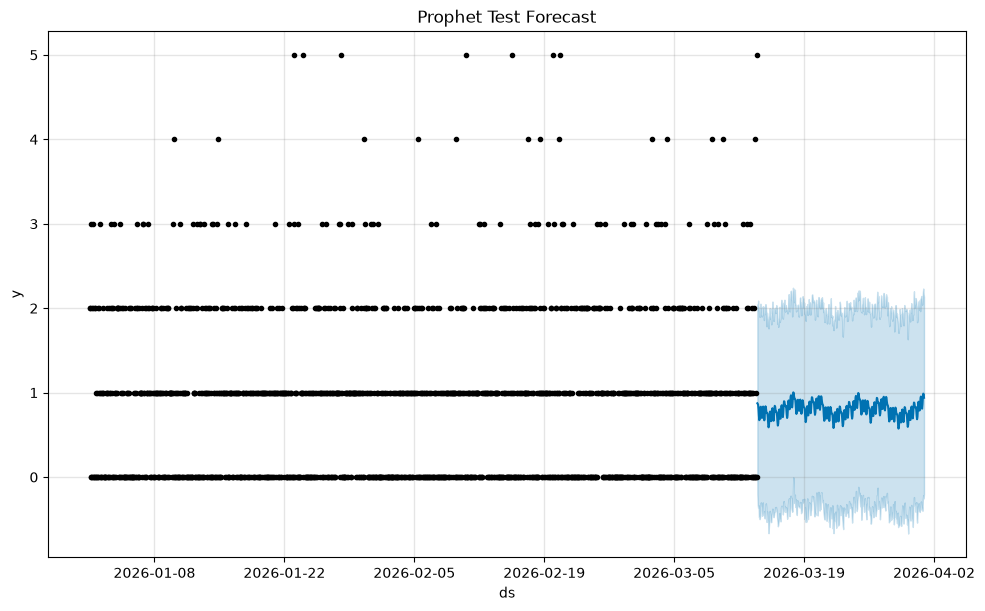

In [6]:
try:
    from prophet import Prophet
    prophet_train = train.rename_axis("ds").reset_index().rename(columns={"order_count":"y"})
    prophet_test = test.rename_axis("ds").reset_index().rename(columns={"order_count":"y"})
    prophet_model = Prophet(daily_seasonality=True, weekly_seasonality=(len(train)>=168), yearly_seasonality=False)
    prophet_model.fit(prophet_train)
    prophet_pred_df = prophet_model.predict(prophet_test[["ds"]])
    prophet_pred = np.maximum(0, prophet_pred_df["yhat"].to_numpy())
    results.append({"Model":"Prophet", **metrics(test,prophet_pred)})
    predictions["Prophet"] = prophet_pred
    import joblib
    joblib.dump(prophet_model, MODELS/"demand_prophet_model.joblib")
    prophet_model.plot(prophet_pred_df); plt.title("Prophet Test Forecast"); plt.show()
except ImportError:
    print("Prophet is optional and not installed. Install with: python -m pip install prophet")
except Exception as e:
    print("Prophet could not be fitted:", repr(e))

## 7. Compare forecasts and plot

,Model,MAE,RMSE,MAPE_percent
0,"ARIMA(1,1,1)",0.751345,0.913677,32.930339
1,Prophet,0.753813,0.917298,37.339180


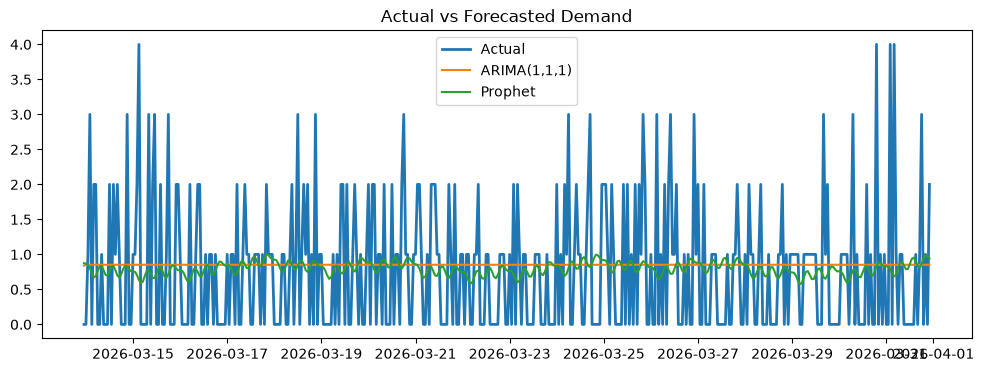

In [7]:
comparison = pd.DataFrame(results).sort_values("MAE")
comparison.to_csv(OUT/"model_comparison.csv",index=False)
display(comparison)
plt.figure(figsize=(12,4))
plt.plot(test.index,test.values,label="Actual",linewidth=2)
for name,pred in predictions.items():
    plt.plot(test.index,pred,label=name)
plt.title("Actual vs Forecasted Demand"); plt.legend(); plt.show()

## 8. Forecast the next 24 hours

,hour,forecast_orders
0,2026-03-31 23:00:00,0.78
1,2026-04-01 00:00:00,0.79
2,2026-04-01 01:00:00,0.79
3,2026-04-01 02:00:00,0.79
4,2026-04-01 03:00:00,0.79
5,2026-04-01 04:00:00,0.79
6,2026-04-01 05:00:00,0.79
7,2026-04-01 06:00:00,0.79
8,2026-04-01 07:00:00,0.79
9,2026-04-01 08:00:00,0.79


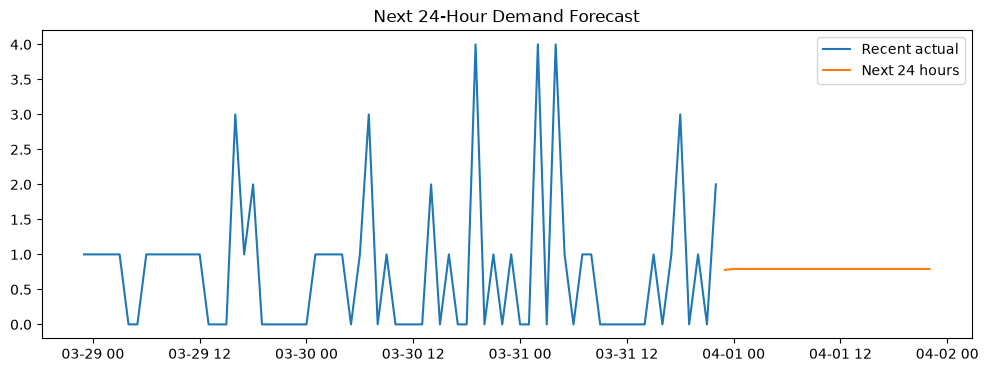

Day 5 outputs saved to /home/nineleaps/Downloads/uber_eats-ML/outputs/demand_forecasting


In [8]:
final_model = ARIMA(series, order=(1,1,1)).fit()
future_values = np.maximum(0,np.asarray(final_model.forecast(steps=24)))
future_index = pd.date_range(series.index.max()+pd.Timedelta(hours=1),periods=24,freq="h")
future = pd.DataFrame({"hour":future_index,"forecast_orders":np.round(future_values,2)})
future.to_csv(OUT/"next_24_hour_demand_forecast.csv",index=False)
final_model.save(MODELS/"demand_arima_final_model.pkl")
display(future)
plt.figure(figsize=(12,4))
plt.plot(series.index[-min(72,len(series)):],series.tail(72),label="Recent actual")
plt.plot(future_index,future_values,label="Next 24 hours")
plt.legend(); plt.title("Next 24-Hour Demand Forecast"); plt.show()
(OUT/"business_interpretation.txt").write_text(
    f"Observed hourly rows: {len(hourly)}\nPeak average hour: {int(by_hour.idxmax())}\n"
    "Use forecasts as planning estimates, not guaranteed order counts.\n",encoding="utf-8")
print("Day 5 outputs saved to",OUT)